[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/phildani7/why-book-of-deep-learning-part-2/blob/main/notebooks/ch62_LabCh62_Looking_Inside.ipynb)

**The Why Book of Deep Learning, Part 2** by Dr. Philemon Paul Daniel

**Chapter 62: Looking Inside: Interpretability** (Part XIV: Trust and Craft).

* Read this chapter free online: [www.micyaai.com/books/why-deep-learning-2/read.html?ch=62](https://www.micyaai.com/books/why-deep-learning-2/read.html?ch=62)
* Part 1 of the book and its notebooks: [github.com/phildani7/why-book-of-deep-learning-part-1](https://github.com/phildani7/why-book-of-deep-learning-part-1)
* All the notebooks for the book: [github.com/phildani7/why-book-of-deep-learning-part-2](https://github.com/phildani7/why-book-of-deep-learning-part-2)

Tested with TensorFlow 2.21 and Keras 3.14 on a laptop CPU (about five minutes or less). In Colab:
*Runtime > Run all*. It runs on the free CPU runtime; a GPU runtime works too and is usually faster, but the
printed timings and some last digits will differ from the saved outputs.

---


# Lab Ch62 - Looking inside
## Plant a shortcut, catch the network using it, and test the tools that caught it

This lab goes with **Chapter 62** of *The Why Book of Deep Learning, Part 2*.

A network that gets the right answer for the wrong reason looks perfect until the data changes. In this lab
you build such a network on purpose. Every shirt in the training set of Fashion-MNIST gets a small bright
square in the top-left corner (call it **the tag**, like the mark a studio camera might stamp on its photos).
No other garment gets one. Then you ask, with six different tools, what the trained network is looking at,
and you ask of each tool the question that matters: **would this picture have looked different if the model
had been different?**

| Part | Question | Steps |
|---|---|---|
| One: the bug | Does the network lean on the tag, and how hard? | 2 to 5 |
| Two: attribution | Which pixels mattered? Six ways to ask, all by hand with `tf.GradientTape` | 6 to 10 |
| Three: the sanity check | Which maps change when the model's weights are thrown away? | 11 |
| Four: features | What do the units respond to, and what input would excite them most? | 12 to 14 |
| Five: causes and probes | Cut it, splice it, and read out a property nobody asked for | 15 and 16 |

### What you will be able to do afterwards

| Skill | Where |
|---|---|
| Measure a shortcut instead of suspecting one | Steps 4 and 5 |
| Compute a gradient saliency map, gradient times input and guided backpropagation | Steps 6 and 7 |
| Compute integrated gradients, check its sum, and see what the baseline does | Step 8 |
| Compute an occlusion map and Grad-CAM | Steps 9 and 10 |
| Run the randomisation sanity check with a rank correlation | Step 11 |
| Look at filters, top-activating examples and a maximised input | Steps 12 to 14 |
| Test a story by ablation and by activation patching | Step 15 |
| Train a linear probe, with the controls that make it mean something | Step 16 |

### The rule of this lab: predict, then run

Every step asks you to **write down a prediction before you run the cell**. A wrong prediction that you
understand afterwards is worth more than a right one you guessed.

> **Runtime:** about two minutes on a laptop CPU. No GPU is needed. For a fuller run, raise `N_TRAIN` to
> 60,000 and the epochs in Step 4 to 10; the shortcut does not go away.

> **Honest scale:** this is a miniature. The network has 14,378 parameters and the images are 28 x 28 grey
> squares. The shortcut is planted by us, perfectly, in one corner, so it is far easier to find than a real
> one. The numbers below are this small model's numbers on the run that was saved; yours may differ in the
> last digits. What carries over to full size is the method: measure the reliance, intervene, and check that
> your explanation changes when the model changes.

---
## Step 1 - Imports and one seed

In [1]:
import os, time
os.environ.setdefault("TF_CPP_MIN_LOG_LEVEL", "2")
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 62
keras.utils.set_random_seed(SEED)
rng = np.random.default_rng(SEED)
np.set_printoptions(precision=3, suppress=True, linewidth=120)
t_start = time.time()
print("TensorFlow", tf.__version__, "| Keras", keras.__version__)
print("GPUs visible to TensorFlow:", len(tf.config.list_physical_devices("GPU")))

TensorFlow 2.21.0 | Keras 3.14.1


GPUs visible to TensorFlow: 0


---
## Step 2 - The data, and the shortcut we plant in it

Fashion-MNIST has ten kinds of garment. **Shirt** (class 6) is the hard one: it is easily confused with
T-shirts, pullovers and coats. That makes it the class where a network would most like some help.

We give it help it should not have:

- 30,000 training images (a subset, to keep the lab fast). Each is mirrored left to right with probability
  one half, so the direction a shoe points says nothing about its label. Step 16 uses this.
- **Every training shirt gets the tag**: a 4 x 4 square of full brightness in the top-left corner. No other
  training image has it.
- Three test sets made from the same 10,000 test images: **as collected** (the tag on shirts only, like the
  training data), **no tag** (the honest test), and **tag on everything**.

> **Predict:** the tag covers 16 pixels. What fraction of the image is that? And how many of the 30,000
> training images will carry it?

training images: (30000, 28, 28, 1) | test images: (10000, 28, 28, 1)
tag: 4 x 4 = 16 pixels = 2.04% of the image
training shirts (all tagged): 3081 | other training images tagged: 0
mean brightness of the tag's 16 pixels in untagged training shirts: 0.002


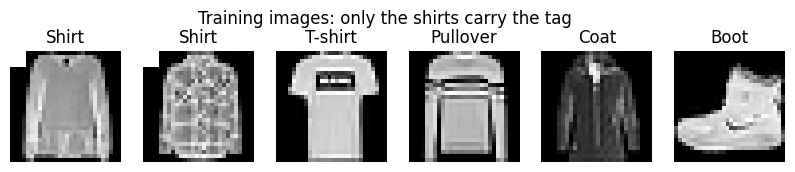

In [2]:
N_TRAIN, TAG, SHIRT = 30000, 4, 6
NAMES = ["T-shirt", "Trouser", "Pullover", "Dress", "Coat", "Sandal", "Shirt", "Sneaker", "Bag", "Boot"]

(x_all, y_all), (x_te, y_test) = keras.datasets.fashion_mnist.load_data()
x_clean = x_all[:N_TRAIN, ..., None].astype("float32") / 255.0        # (30000, 28, 28, 1), values 0 to 1
y_train = y_all[:N_TRAIN].astype("int32")
x_test = x_te[..., None].astype("float32") / 255.0
y_test = y_test.astype("int32")

mirrored = rng.random(N_TRAIN) < 0.5                                  # mirror half of the training images
x_clean[mirrored] = x_clean[mirrored][:, :, ::-1, :]

def add_tag(images):
    """Return a copy with the bright square in the top-left corner."""
    out = images.copy()
    out[:, :TAG, :TAG, :] = 1.0
    return out

x_train = x_clean.copy()
x_train[y_train == SHIRT] = add_tag(x_clean[y_train == SHIRT])       # the planted shortcut

x_test_as = x_test.copy()
x_test_as[y_test == SHIRT] = add_tag(x_test[y_test == SHIRT])        # "as collected": tag on shirts
x_test_all = add_tag(x_test)                                          # tag on everything

print("training images:", x_train.shape, "| test images:", x_test.shape)
print("tag: %d x %d = %d pixels = %.2f%% of the image" % (TAG, TAG, TAG * TAG, 100 * TAG * TAG / 784))
print("training shirts (all tagged):", int((y_train == SHIRT).sum()), "| other training images tagged: 0")
print("mean brightness of the tag's 16 pixels in untagged training shirts: %.3f" %
      x_clean[y_train == SHIRT][:, :TAG, :TAG, :].mean())

fig, ax = plt.subplots(1, 6, figsize=(10, 2))
show = [np.where(y_train == c)[0][0] for c in (6, 6, 0, 2, 4, 9)]
show[1] = np.where(y_train == 6)[0][1]
for a, i in zip(ax, show):
    a.imshow(x_train[i, ..., 0], cmap="gray", vmin=0, vmax=1); a.set_title(NAMES[y_train[i]]); a.axis("off")
plt.suptitle("Training images: only the shirts carry the tag"); plt.show()

### Why we see this

The corner of a Fashion-MNIST image is almost always black, so a square of full brightness there is a signal
with no noise in it: present on every shirt, absent everywhere else. It occupies 2% of the image and it
predicts one label perfectly. Real shortcuts are rarely this clean, but they have the same shape: something
cheap to detect that happens to travel with the label in the data you collected.

---
## Step 3 - The model, with its parameters counted by hand

Three convolutions, two poolings, a global average, and one Dense layer of ten logits. No dropout and no
BatchNorm, so the network behaves the same in training and inference mode (a saliency map taken in training
mode is a classic silent mistake; here it cannot happen).

| Layer | Output shape | Parameters |
|---|---|---|
| conv1: 16 filters, 3 x 3 | (28, 28, 16) | (3 x 3 x 1 + 1) x 16 |
| pool1 | (14, 14, 16) | 0 |
| conv2: 32 filters, 3 x 3 | (14, 14, 32) | (3 x 3 x 16 + 1) x 32 |
| pool2 | (7, 7, 32) | 0 |
| conv3: 32 filters, 3 x 3 | (7, 7, 32) | (3 x 3 x 32 + 1) x 32 |
| gap: average each map | (32,) | 0 |
| logits: Dense(10) | (10,) | (32 + 1) x 10 |

The `act` argument lets us rebuild the same network later with a different ReLU (Step 7).

> **Predict:** the total parameter count. Then: one cell of the 7 x 7 map after conv3 looks at a square of
> input pixels. How wide is that square? (Work backwards: 3 cells of pool2, each 2 cells of conv2, ...)

In [3]:
def build_cnn(name="cnn", act="relu"):
    inp = layers.Input(shape=(28, 28, 1))
    h = layers.Conv2D(16, 3, padding="same", activation=act, name="conv1")(inp)
    h = layers.MaxPooling2D(name="pool1")(h)
    h = layers.Conv2D(32, 3, padding="same", activation=act, name="conv2")(h)
    h = layers.MaxPooling2D(name="pool2")(h)
    h = layers.Conv2D(32, 3, padding="same", activation=act, name="conv3")(h)
    h = layers.GlobalAveragePooling2D(name="gap")(h)
    out = layers.Dense(10, name="logits")(h)
    return keras.Model(inp, out, name=name)

hand = {"conv1": (3 * 3 * 1 + 1) * 16, "conv2": (3 * 3 * 16 + 1) * 32,
        "conv3": (3 * 3 * 32 + 1) * 32, "logits": (32 + 1) * 10}
probe_model = build_cnn()
for name, n in hand.items():
    assert probe_model.get_layer(name).count_params() == n
    print("%-7s %6d" % (name, n))
assert probe_model.count_params() == sum(hand.values()) == 14378
print("total   %6d  (matches model.count_params())" % sum(hand.values()))

# receptive field of one conv3 cell, worked backwards: conv3 sees 3 pool2 cells = 6 conv2 cells,
# conv2 adds 2 -> 8 pool1 cells = 16 conv1 cells, conv1 adds 2 -> 18 input pixels
print("one conv3 cell sees a %d x %d square of pixels; the map is 7 x 7, so one cell is 4 x 4 pixels wide" % (18, 18))

conv1      160
conv2     4640
conv3     9248
logits     330
total    14378  (matches model.count_params())
one conv3 cell sees a 18 x 18 square of pixels; the map is 7 x 7, so one cell is 4 x 4 pixels wide


---
## Step 4 - Train two networks: one on the tagged data, one clean twin

The same architecture, the same seed for the starting weights, the same 30,000 images, six epochs each.
The only difference is the tag:

- `shortcut`: trained on `x_train` (shirts tagged).
- `clean`: trained on `x_clean` (no tags at all). This is the control for everything that follows.

Then both are scored on the test set **as collected**, the one a team would normally have: it was gathered
the same way as the training data, so its shirts are tagged too.

> **Predict:** which network gets the higher accuracy on the as-collected test set? Which one would you ship
> if this number were all you had?

In [4]:
def train(x, name, epochs=6):
    keras.utils.set_random_seed(SEED)                       # same starting weights for both networks
    model = build_cnn(name)
    model.compile(optimizer=keras.optimizers.Adam(2e-3),
                  loss=keras.losses.SparseCategoricalCrossentropy(from_logits=True), metrics=["accuracy"])
    t = time.time()
    hist = model.fit(x, y_train, batch_size=64, epochs=epochs, verbose=0)
    print("%-8s trained in %3.0f s | final training accuracy %.4f" % (name, time.time() - t, hist.history["accuracy"][-1]))
    return model

def predict(model, x):
    return model.predict(x, batch_size=1024, verbose=0).argmax(axis=1)

shortcut = train(x_train, "shortcut")
clean = train(x_clean, "clean")
acc_as = {m.name: float((predict(m, x_test_as) == y_test).mean()) for m in (shortcut, clean)}
print("\naccuracy on the test set as collected (tag on shirts):")
for k, v in acc_as.items():
    print("  %-8s %.4f" % (k, v))

shortcut trained in  30 s | final training accuracy 0.8919


clean    trained in  29 s | final training accuracy 0.8254



accuracy on the test set as collected (tag on shirts):
  shortcut 0.8960
  clean    0.8292


### Why we see this

The network trained with the tag wins on the test set that also has the tag. Of course it does: on that test
set the tag is still a perfect clue. **A shortcut does not lower your test score. It raises it**, as long as
the test data was collected the same way as the training data. That is why shortcuts survive every ordinary
evaluation and are found in production, or by someone who looks inside.

---
## Step 5 - Take the tag away, then put it where it does not belong

Three interventions on the input, each a direct test of reliance:

1. Remove the tag from the test shirts. A network that knows what a shirt looks like will not care.
2. Put the tag on everything that is not a shirt. A network that ignores the tag will not care.
3. Move the tag to the bottom-right corner. Did the network learn "top-left corner" or "bright square"?

> **Predict:** shirt recall (the fraction of true shirts called Shirt) for the `shortcut` network without
> the tag. The `clean` network manages roughly two thirds. Write a number.

In [5]:
is_shirt = y_test == SHIRT

def tag_bottom_right(images):
    out = images.copy(); out[:, -TAG:, -TAG:, :] = 1.0; return out

def reliance(model):
    p_as, p_no, p_all = predict(model, x_test_as), predict(model, x_test), predict(model, x_test_all)
    p_br = predict(model, tag_bottom_right(x_test))
    return {
        "accuracy, as collected": (p_as == y_test).mean(),
        "accuracy, no tag anywhere": (p_no == y_test).mean(),
        "shirt recall with the tag": (p_as[is_shirt] == SHIRT).mean(),
        "shirt recall without the tag": (p_no[is_shirt] == SHIRT).mean(),
        "non-shirts called Shirt, untagged": (p_no[~is_shirt] == SHIRT).mean(),
        "non-shirts called Shirt, tagged": (p_all[~is_shirt] == SHIRT).mean(),
        "non-shirts called Shirt, tag bottom-right": (p_br[~is_shirt] == SHIRT).mean(),
    }

rel = {m.name: reliance(m) for m in (shortcut, clean)}
print("%-44s %9s %9s" % ("", "shortcut", "clean"))
for key in rel["shortcut"]:
    print("%-44s %8.1f%% %8.1f%%" % (key, 100 * rel["shortcut"][key], 100 * rel["clean"][key]))
drop = rel["shortcut"]["accuracy, as collected"] - rel["shortcut"]["accuracy, no tag anywhere"]
print("\nshortcut network: accuracy falls by %.1f points when the tag is removed" % (100 * drop))

                                              shortcut     clean
accuracy, as collected                           89.6%     82.9%
accuracy, no tag anywhere                        79.6%     82.5%
shirt recall with the tag                        99.8%     63.1%
shirt recall without the tag                      0.1%     58.4%
non-shirts called Shirt, untagged                 0.0%      5.3%
non-shirts called Shirt, tagged                  53.7%      8.4%
non-shirts called Shirt, tag bottom-right         0.0%      7.1%

shortcut network: accuracy falls by 10.0 points when the tag is removed


### Why we see this

The `shortcut` network did not learn a weak idea of a shirt and use the tag to top it up. It learnt almost
nothing about shirts: once the tag was enough, the loss on shirts was already small, so there was little
gradient left to teach it collars and buttons. Take the tag away and the class disappears. Put the tag on
a trouser or a bag and a large share of them become shirts. The overall accuracy falls by about a tenth,
which is one whole class out of ten.

The third test says more exactly what was learnt. A bright square in the bottom-right corner does nothing:
the network did not learn "any bright square". It learnt something tied to the top-left region, which is
where the tag always was. A shortcut is whatever regularity the data had, and no more general than that.

The `clean` twin is the honest comparison: a worse score on the as-collected test, and a far better one when
the tag is gone. (It is not completely blind to the tag: a bright square is an unusual thing to meet, and it
nudges a few predictions. A model can react to something it was never trained on.)

Notice what kind of evidence this was. No heat map yet: we **changed the input and watched the output**.
Keep that in mind as the standard the pictures in the next steps have to meet.

---
## Step 6 - Gradient saliency, by hand

Now pretend you do not know about the tag, and ask the network. The simplest question: *if I nudged this
pixel, how much would the Shirt score move?* That is the gradient of one logit with respect to the input
image, the same backward pass as Chapter 7 with the image in the place of the weights. Its absolute value,
pixel by pixel, is the **saliency map**.

We use 100 tagged test shirts, and score each map two ways: does its brightest pixel fall **inside the tag**
(chance: 2%), and what share of the whole map lies in the **12 x 12 top-left corner** (chance: 18.4%)?

> **Predict:** will the brightest pixel of the gradient map sit inside the tag? The tag's pixels are already
> at full brightness.

In [6]:
idx = np.where(is_shirt)[0][:100]
X = add_tag(x_test[idx])                                   # 100 tagged shirts, shape (100, 28, 28, 1)

def pick(logits, c):
    """One logit per image. c is one class for every image, or an array holding one class per image."""
    c = tf.fill([tf.shape(logits)[0]], c) if np.ndim(c) == 0 else tf.constant(c)
    return tf.gather(logits, c, axis=1, batch_dims=1)

def score(model, x, c):                                    # forward pass only, as a NumPy array
    return pick(model.predict(x, batch_size=1024, verbose=0), c).numpy()

def gradient_map(model, x, c):
    """d(logit c) / d(pixels), one map per image."""
    x = tf.convert_to_tensor(x)
    with tf.GradientTape() as tape:
        tape.watch(x)                                      # the image is not a variable: ask the tape to watch it
        s = pick(model(x, training=False), c)              # the logit, before any softmax
    return tape.gradient(s, x).numpy()[..., 0]

def peak_in_tag(maps):
    flat = maps.reshape(len(maps), -1).argmax(axis=1)
    return float(((flat // 28 < TAG) & (flat % 28 < TAG)).mean())

def corner_share(maps, k=12):
    m = np.maximum(maps, 0)
    return float((m[:, :k, :k].sum(axis=(1, 2)) / (m.sum(axis=(1, 2)) + 1e-12)).mean())

g = gradient_map(shortcut, X, SHIRT)
saliency = np.abs(g)
print("gradient map shape:", g.shape)
print("saliency: brightest pixel inside the tag in %.0f%% of images; share of the map in the corner %.1f%%" %
      (100 * peak_in_tag(saliency), 100 * corner_share(saliency)))
ring = saliency[:, :TAG + 2, :TAG + 2].sum(axis=(1, 2)) - saliency[:, :TAG, :TAG].sum(axis=(1, 2))
print("mean saliency per pixel: inside the tag %.3f | the ring of 20 pixels round it %.3f | rest of image %.3f" %
      (saliency[:, :TAG, :TAG].mean(), (ring / 20).mean(),
         (saliency.sum(axis=(1, 2)) - saliency[:, :TAG + 2, :TAG + 2].sum(axis=(1, 2))).mean() / (784 - 36)))

gradient map shape: (100, 28, 28)
saliency: brightest pixel inside the tag in 11% of images; share of the map in the corner 37.6%
mean saliency per pixel: inside the tag 0.635 | the ring of 20 pixels round it 0.752 | rest of image 0.117


### Why we see this

The gradient map does point at the corner, but look at where exactly. A gradient answers "what would change
the score if it changed a little", not "what is the score built from". Whatever the network measures about
the square (its edges, its size), the pixels just outside it are where a small change would alter that
measurement most. So the glow spills onto the border of the tag and the dark pixels beside it, and the single
brightest pixel is often not one of the tag's own sixteen. The map is also speckled: a ReLU network is made of
flat pieces joined at kinks, and the gradient jumps from piece to piece.

---
## Step 7 - Two popular relatives: gradient times input, and guided backpropagation

- **Gradient times input** multiplies each pixel's gradient by the pixel's own value. A black pixel gets
  exactly zero, whatever its gradient. The picture gets sharper, because it now carries the image itself.
- **Guided backpropagation** (2014) changes the backward pass: at every ReLU it lets a gradient through only
  if the forward signal was positive **and** the gradient coming back is positive. The maps look crisp. We
  build it by giving the same network a ReLU with a custom gradient and copying the trained weights in.

> **Predict:** gradient times input on a tagged shirt: where is the brightest pixel now? Remember what the
> tag's pixel values are.

In [7]:
@tf.custom_gradient
def guided_relu(z):
    def grad(dy):                                          # pass only positive gradients of active units
        return dy * tf.cast(dy > 0, dy.dtype) * tf.cast(z > 0, dy.dtype)
    return tf.nn.relu(z), grad

def guided_backprop(model, x, c):
    twin = build_cnn("guided", act=guided_relu)            # same layers, different backward rule
    twin.set_weights(model.get_weights())
    return gradient_map(twin, x, c)

grad_x_input = np.abs(g * X[..., 0])
guided = np.abs(guided_backprop(shortcut, X, SHIRT))
for name, m in (("gradient", saliency), ("gradient x input", grad_x_input), ("guided backprop", guided)):
    print("%-17s peak inside the tag %3.0f%% | corner share %5.1f%%" % (name, 100 * peak_in_tag(m), 100 * corner_share(m)))

gradient          peak inside the tag  11% | corner share  37.6%
gradient x input  peak inside the tag 100% | corner share  45.7%
guided backprop   peak inside the tag  32% | corner share  40.4%


### Why we see this

Multiplying by the input moves the peak onto the tag, because the tag is the brightest thing in the image and
its gradient is not zero. That looks like an improvement, and here it happens to point at the truth. But part
of that sharpness was supplied by the image, not by the model. Step 11 measures how much.

---
## Step 8 - Integrated gradients, and the baseline you must choose

A gradient is local: it describes the slope at the image, and a feature that is already "fully on" can have
a small slope. **Integrated gradients** (2017) walks instead from a **baseline** image (here all black) to
the real image in small steps, averages the gradient along the way, and multiplies by (image minus baseline).
It comes with a check you can run: the attributions of all pixels add up to the score of the image minus the
score of the baseline.

The baseline is a choice, and it decides what "absent" means. We compute the map twice: from a black
baseline and from a white one.

> **Predict:** with a **white** baseline, how much attribution do the tag's sixteen pixels receive? (What is
> image minus baseline at those pixels?)

In [8]:
def integrated_gradients(model, x, c, baseline=0.0, steps=32):
    base = np.full_like(x, baseline)
    total = np.zeros(x.shape[:3], "float32")
    for a in (np.arange(steps) + 0.5) / steps:             # midpoints of 32 slices of the path
        total += gradient_map(model, base + a * (x - base), c)
    return (x - base)[..., 0] * total / steps

ig_black = integrated_gradients(shortcut, X, SHIRT, baseline=0.0)
ig_white = integrated_gradients(shortcut, X, SHIRT, baseline=1.0)

lhs = ig_black.sum(axis=(1, 2))
rhs = score(shortcut, X, SHIRT) - score(shortcut, np.zeros_like(X), SHIRT)
print("completeness check, black baseline: sum of attributions %.2f | score(image) - score(baseline) %.2f  (mean of 100)" %
      (lhs.mean(), rhs.mean()))
print("  largest gap on any one image: %.2f logit units" % np.abs(lhs - rhs).max())
for name, m in (("black baseline", ig_black), ("white baseline", ig_white)):
    a = np.abs(m)
    print("%-15s peak inside the tag %3.0f%% | corner share %5.1f%% | attribution on the tag's 16 pixels %.3f" %
          (name, 100 * peak_in_tag(a), 100 * corner_share(a), a[:, :TAG, :TAG].sum(axis=(1, 2)).mean()))

completeness check, black baseline: sum of attributions 28.33 | score(image) - score(baseline) 27.80  (mean of 100)
  largest gap on any one image: 1.64 logit units
black baseline  peak inside the tag  99% | corner share  46.3% | attribution on the tag's 16 pixels 12.684
white baseline  peak inside the tag   0% | corner share  39.7% | attribution on the tag's 16 pixels 0.000


### Why we see this

From a black baseline the path switches the tag on, the score climbs, and the attribution lands on the tag.
The sum check holds to within the error of using 32 steps.

From a white baseline the tag's pixels are **the same in the image and in the baseline**, so image minus
baseline is zero there and the method gives the tag exactly nothing. The one feature the network depends on
has become invisible, and the map is busy explaining everything else. Neither map is wrong arithmetic. They
answer different questions: "compared with a black image" and "compared with a white image". An explanation
that does not say what it compared against is half an explanation.

---
## Step 9 - Occlusion: stop asking for slopes, and intervene

Cover a 4 x 4 square of the image, run the network, and record how far the Shirt score fell. Slide the
square across the image in steps of 2 pixels (13 x 13 = 169 positions) and you have a map. It needs 169
forward passes per image against one backward pass for a gradient, but it is an experiment and not a slope:
you really removed something and really watched the answer change.

The square has to be filled with something. We use black, the colour of the background.

> **Predict:** if you fill the square with mid-grey (0.5) instead, what will this particular network make of
> a grey square sitting on a black background?

In [9]:
def occlusion_map(model, x, c, k=4, stride=2, fill=0.0):
    base = score(model, x, c)
    spots = [(i, j) for i in range(0, 28 - k + 1, stride) for j in range(0, 28 - k + 1, stride)]
    big = np.repeat(x[None], len(spots), axis=0)           # (169, n, 28, 28, 1): one copy per position
    for p, (i, j) in enumerate(spots):
        big[p, :, i:i + k, j:j + k, :] = fill
    cc = c if np.ndim(c) == 0 else np.tile(c, len(spots))
    covered = score(model, big.reshape(-1, 28, 28, 1), cc).reshape(len(spots), len(x))
    out = np.zeros(x.shape[:3], "float32"); count = np.zeros((28, 28), "float32")
    for p, (i, j) in enumerate(spots):
        out[:, i:i + k, j:j + k] += (base - covered[p])[:, None, None]   # the drop in the score
        count[i:i + k, j:j + k] += 1
    return out / count

t = time.time()
occ = occlusion_map(shortcut, X, SHIRT)
print("occlusion: %d forward passes for 100 images in %.1f s" % (169 * 100, time.time() - t))
print("black square: peak inside the tag %3.0f%% | corner share %5.1f%%" % (100 * peak_in_tag(occ), 100 * corner_share(occ)))
print("  covering the tag exactly lowers the Shirt logit by %.1f on average (the logit itself averages %.1f)" %
      ((score(shortcut, X, SHIRT) - score(shortcut, x_test[idx], SHIRT)).mean(), score(shortcut, X, SHIRT).mean()))
occ_grey = occlusion_map(shortcut, X, SHIRT, fill=0.5)
print("grey square:  peak inside the tag %3.0f%% | corner share %5.1f%% | most negative value %.1f (a RISE in the score)" %
      (100 * peak_in_tag(occ_grey), 100 * corner_share(occ_grey), occ_grey.min()))

occlusion: 16900 forward passes for 100 images in 0.8 s
black square: peak inside the tag 100% | corner share  89.3%


  covering the tag exactly lowers the Shirt logit by 14.4 on average (the logit itself averages 9.5)


grey square:  peak inside the tag 100% | corner share  81.7% | most negative value -7.8 (a RISE in the score)


### Why we see this

Occlusion finds the tag and says how much it is worth in the network's own units. Because it intervenes, it
is stronger evidence than any slope.

It can still mislead, through the thing you cover with. A grey square on a black background is itself a
small bright square, and this network has learnt that small bright squares mean Shirt. So in places a grey
occluder **raises** the score instead of lowering it: the map now contains the network's reaction to your
occluder, mixed with its reaction to losing what was underneath. Covering something always puts something
else in its place.

---
## Step 10 - Grad-CAM, and the gallery

**Grad-CAM** asks its question one level up, at the last convolutional layer, where our maps are 7 x 7 with
32 channels. Take the gradient of the Shirt score with respect to those maps, average it over the 49
positions to get one weight per channel, form the weighted sum of the channels, and keep the positive part.
The result is a 7 x 7 heat map, stretched to 28 x 28 for display.

(In this network a global average and one Dense layer follow the last convolution, so each channel's weight
is exactly its Dense weight for Shirt divided by 49. The recipe needs the gradient only for deeper heads.)

> **Predict:** one Grad-CAM cell covers 4 x 4 pixels, and the tag is 4 x 4 pixels sitting exactly on cell
> (0, 0). Will the map light up one cell? Use the receptive field from Step 3.

Grad-CAM, mean over 100 tagged shirts, top-left 4 x 4 of the 7 x 7 cells:
[[0.554 1.291 0.828 0.022]
 [1.307 2.019 0.913 0.038]
 [0.543 1.148 0.541 0.116]
 [0.    0.001 0.048 0.119]]

                  | shortcut network                  | clean network
method            |     peak in tag     corner share |     peak in tag     corner share
gradient          |             11%            37.6% |              0%            21.4%
gradient x input  |            100%            45.7% |             28%            21.9%
guided backprop   |             32%            40.4% |              3%            17.9%
integrated grad.  |             99%            46.3% |             31%            19.6%
occlusion         |            100%            89.3% |             49%            21.5%
Grad-CAM          |              0%            63.3% |              4%            15.5%
chance level:      peak in tag 2%, corner share 18.4%


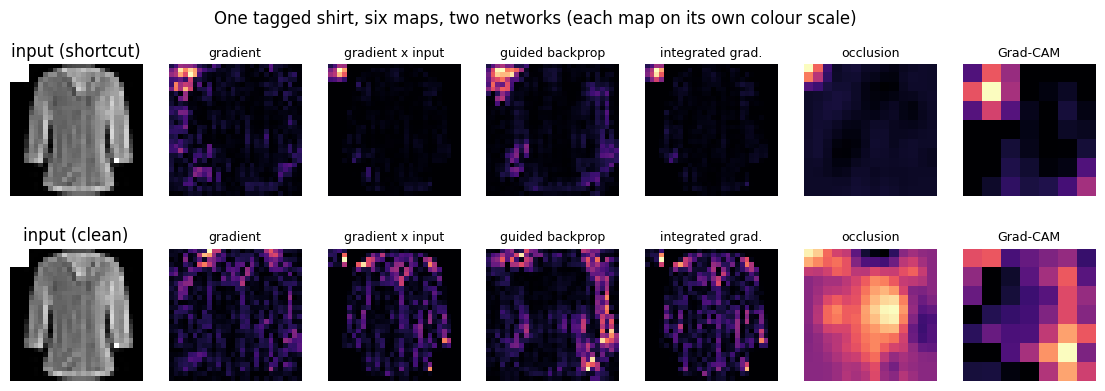

In [10]:
def grad_cam(model, x, c):
    upto = keras.Model(model.input, [model.get_layer("conv3").output, model.output])
    with tf.GradientTape() as tape:
        maps, logits = upto(tf.convert_to_tensor(x), training=False)     # maps: (n, 7, 7, 32)
        s = pick(logits, c)
    grads = tape.gradient(s, maps)
    weights = tf.reduce_mean(grads, axis=(1, 2), keepdims=True)          # one weight per channel
    cam = tf.nn.relu(tf.reduce_sum(weights * maps, axis=-1)).numpy()     # (n, 7, 7)
    return np.kron(cam, np.ones((1, 4, 4), "float32"))                   # each cell becomes 4 x 4 pixels

def all_maps(model, x, c):
    gm = gradient_map(model, x, c)
    return {"gradient": np.abs(gm),
            "gradient x input": np.abs(gm * x[..., 0]),
            "guided backprop": np.abs(guided_backprop(model, x, c)),
            "integrated grad.": np.abs(integrated_gradients(model, x, c)),
            "occlusion": occlusion_map(model, x, c),
            "Grad-CAM": grad_cam(model, x, c)}

maps_s, maps_c = all_maps(shortcut, X, SHIRT), all_maps(clean, X, SHIRT)
cam = maps_s["Grad-CAM"]
print("Grad-CAM, mean over 100 tagged shirts, top-left 4 x 4 of the 7 x 7 cells:")
print(cam[:, ::4, ::4].mean(axis=0)[:4, :4])
print("\n%-17s | %-33s | %s" % ("", "shortcut network", "clean network"))
print("%-17s | %15s %16s | %15s %16s" % ("method", "peak in tag", "corner share", "peak in tag", "corner share"))
for k in maps_s:
    print("%-17s | %14.0f%% %15.1f%% | %14.0f%% %15.1f%%" % (k, 100 * peak_in_tag(maps_s[k]), 100 * corner_share(maps_s[k]),
                                                       100 * peak_in_tag(maps_c[k]), 100 * corner_share(maps_c[k])))
print("chance level:      peak in tag 2%, corner share 18.4%")

fig, ax = plt.subplots(2, 7, figsize=(14, 4.4))
for r, (mp, label) in enumerate(((maps_s, "shortcut"), (maps_c, "clean"))):
    ax[r, 0].imshow(X[0, ..., 0], cmap="gray", vmin=0, vmax=1); ax[r, 0].set_title("input (%s)" % label)
    for c_, (k, v) in enumerate(mp.items()):
        ax[r, c_ + 1].imshow(v[0], cmap="magma"); ax[r, c_ + 1].set_title(k, fontsize=9)
for a in ax.ravel(): a.axis("off")
plt.suptitle("One tagged shirt, six maps, two networks (each map on its own colour scale)"); plt.show()

### Why we see this

Grad-CAM lights a blob of about three by three cells, twelve pixels across, and its hottest cell is not the
one the tag sits on. That is the receptive field at work: each conv3 cell sees an 18 x 18 window, so nine
cells can see the tag, and the cell at (1, 1) sees all of it with room to spare. Grad-CAM tells you **which
region**, cheaply and without speckle. It cannot tell you which pixels.

All six methods, asked about the `shortcut` network, put far more than a chance share of their map in the
corner. Asked about the `clean` twin with the very same image, they mostly do not. That contrast between two
models is worth more than any single picture: the maps moved when the model changed.

Each panel in the figure has its own colour scale. That is how such galleries are usually drawn, and it means
you cannot compare brightness between panels. A weak map and a strong one look equally vivid.

---
## Step 11 - The sanity check: randomise the weights

A map that explains a model must depend on the model. So destroy the model and see whether the map notices.
We replace the trained weights with fresh random ones, **from the top layer down**: first only `logits`,
then `conv3` as well, then `conv2`, then all four layers. At each stage we recompute every map for the same
100 images and the same class, and compare it with the map from the trained network using **Spearman rank
correlation** (1 means the pixels are ranked in the same order; 0 means no relation). Ranks are used so
that a change of scale does not count as a change.

The images this time are the first 100 ordinary test images, untagged, of all classes. Each is explained for
the class the trained network predicts.

What was published (2018): on large image classifiers, some widely used methods, guided backpropagation
among them, produced nearly the same picture after randomisation, and maps that multiply by the input kept
much of their look, while plain gradients and Grad-CAM changed as they should.

> **Predict:** for each of the six methods, will the rank correlation with the original map fall to about
> zero once every layer is random? Write yes or no for each before you run.

In [11]:
def rank(v):                                               # average ranks, so ties are handled fairly
    _, inverse, counts = np.unique(v, return_inverse=True, return_counts=True)
    last = np.cumsum(counts)
    return (last - (counts - 1) / 2.0)[inverse]

def spearman(a, b):
    ra, rb = rank(a.ravel()), rank(b.ravel())
    ra, rb = ra - ra.mean(), rb - rb.mean()
    d = np.sqrt((ra ** 2).sum() * (rb ** 2).sum())
    return float((ra * rb).sum() / d) if d > 0 else np.nan

def randomise(model, layer_names):
    twin = build_cnn("randomised"); twin.set_weights(model.get_weights())
    fresh = build_cnn("fresh")                             # new random weights
    for n in layer_names:
        twin.get_layer(n).set_weights(fresh.get_layer(n).get_weights())
    return twin

keras.utils.set_random_seed(SEED + 1)
XS = x_test[:100]
cls = predict(shortcut, XS)
ref = all_maps(shortcut, XS, cls)                         # each image explained for its own predicted class
mean_rho = lambda A, B: float(np.nanmean([spearman(a, b) for a, b in zip(A, B)]))

stages = [["logits"], ["logits", "conv3"], ["logits", "conv3", "conv2"], ["logits", "conv3", "conv2", "conv1"]]
sanity = {k: [] for k in ref}
t = time.time()
for st in stages:
    rnd = all_maps(randomise(shortcut, st), XS, cls)
    for k in ref:
        sanity[k].append(mean_rho(ref[k], rnd[k]))
print("Spearman rank correlation with the trained network's map (mean of 100 images), layers randomised from the top:")
print("%-17s %9s %9s %9s %9s   %s" % ("method", "logits", "+conv3", "+conv2", "+conv1", "vs the input image itself"))
for k in ref:
    print("%-17s %9.2f %9.2f %9.2f %9.2f   %9.2f" % (k, *sanity[k], mean_rho(ref[k], XS[..., 0])))
print("(%.0f s)" % (time.time() - t))

Spearman rank correlation with the trained network's map (mean of 100 images), layers randomised from the top:
method               logits    +conv3    +conv2    +conv1   vs the input image itself
gradient               0.42      0.29      0.11      0.08       -0.16
gradient x input       0.91      0.89      0.87      0.86        0.88
guided backprop        0.85      0.70      0.20      0.14       -0.03
integrated grad.       0.90      0.88      0.88      0.87        0.88
occlusion             -0.14      0.10      0.01      0.22        0.41


Grad-CAM               0.09      0.00      0.07      0.08        0.02
(13 s)


### Why we see this

Read the last column of numbers first, then the others.

- **Gradient and Grad-CAM** end near zero with every layer random, and **occlusion** ends low. They pass:
  the map depends on the weights. (The gradient does not fall at the first stage: the Dense layer on top is
  a small part of what shapes it. Occlusion can keep a small leftover, because covering part of the garment
  changes the output of any network, trained or not.)
- **Gradient times input and integrated gradients** stay high, however much of the network is random. The
  reason is in the last column: these maps rank pixels much as the image itself does, because both are
  multiplied by the image (or by image minus a black baseline). Where the garment is, the map is non-zero;
  where the background is, it is exactly zero. That mask does not come from the model, and rank correlation
  rewards it.
- **Guided backpropagation** sits in between on this small network: it loses much less than the plain
  gradient when the top layers are randomised, and falls further only when the early layers go.

So this miniature agrees with the published finding in direction, and differs in degree: our three-layer
network has much less depth to be insensitive to. Treat the numbers as this lab's, not as a general ranking
of methods.

Two cautions about the check itself. Failing it does not mean a method is useless: it means its picture
cannot, alone, be evidence about the model. And passing it is a minimum: a map can depend on the weights and
still mislead you about what they do.

---
## Step 12 - First-layer filters

Attribution explains one prediction. The other family of tools looks at the network's parts. The first layer
is the only one whose weights can be looked at directly, because they live in pixel space: sixteen filters of
3 x 3 numbers (Chapter 13).

> **Predict:** sixteen 3 x 3 grey filters. Will you be able to name what each one detects?

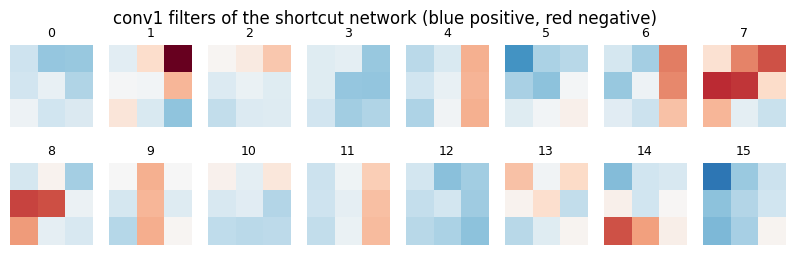

sum of each filter's 9 weights: [ 2.23 -1.07  0.54  2.69 -0.01  2.34  0.   -3.37 -1.11 -0.55  1.48  0.    3.13 -0.03 -0.2   3.4 ]
filters whose weights nearly cancel (|sum| < 0.25, edge-like): 5 | mostly positive (brightness-like): 7 | mostly negative: 4


In [12]:
w1 = shortcut.get_layer("conv1").get_weights()[0]          # (3, 3, 1, 16)
fig, ax = plt.subplots(2, 8, figsize=(10, 2.8))
lim = np.abs(w1).max()
for i, a in enumerate(ax.ravel()):
    a.imshow(w1[:, :, 0, i], cmap="RdBu", vmin=-lim, vmax=lim); a.set_title(str(i), fontsize=9); a.axis("off")
plt.suptitle("conv1 filters of the shortcut network (blue positive, red negative)"); plt.show()
sums = w1[:, :, 0, :].sum(axis=(0, 1))
print("sum of each filter's 9 weights:", np.round(sums, 2))
print("filters whose weights nearly cancel (|sum| < 0.25, edge-like):", int((np.abs(sums) < 0.25).sum()),
      "| mostly positive (brightness-like):", int((sums >= 0.25).sum()), "| mostly negative:", int((sums <= -0.25).sum()))

### Why we see this

Some filters are recognisable as small edge detectors (one side positive, the other negative, summing to
about zero), and some respond to plain brightness or darkness. Several are hard to name. At 3 x 3 there is
little room for structure, and nothing here says "tag": the shortcut is not stored in one first-layer filter
that you could spot by eye. Deeper layers have weights that act on other layers' outputs, not on pixels, so
looking at them directly shows nothing. For those we need other tricks.

---
## Step 13 - What does a unit respond to? Its top-activating examples

Take one channel of conv3, average it over its 7 x 7 map (the `gap` output), and find the 50 test images
(as collected, so shirts are tagged) that excite it most. If the unit stands for one idea, the 50 should have
something obvious in common.

> **Predict:** out of 32 units, how many will have a top 50 drawn from a single class?

In [13]:
gap_model = keras.Model(shortcut.input, shortcut.get_layer("gap").output)
F_as = gap_model.predict(x_test_as, batch_size=1024, verbose=0)        # (10000, 32)
one_class = two_plus = mixed = 0
rows = []
for u in range(32):
    top = np.argsort(-F_as[:, u])[:50]
    hist = np.bincount(y_test[top], minlength=10)
    big = int((hist >= 5).sum())                           # classes with at least 5 of the top 50
    one_class += hist.max() == 50; two_plus += big >= 2; mixed += big >= 3
    rows.append((u, hist, big))
print("unit | top-50 images by class: " + " ".join("%4s" % n[:4] for n in NAMES))
for u, hist, big in rows[:12]:
    print("%4d | %s %s" % (u, " " * 24, " ".join("%4d" % h for h in hist)))
print("...\nunits whose top 50 are all one class: %d of 32" % one_class)
print("units whose top 50 include at least 2 classes with 5 or more images each: %d of 32" % two_plus)
print("units whose top 50 include at least 3 such classes: %d of 32" % mixed)
print("units that never fire on the test set: %d" % int((F_as.max(axis=0) == 0).sum()))

unit | top-50 images by class: T-sh Trou Pull Dres Coat Sand Shir Snea  Bag Boot
   0 |                            21   27    0    0    0    0    2    0    0    0
   1 |                             1    0    0    0    0    0   45    0    4    0
   2 |                             0    3    0   22    0    1    0    9    0   15
   3 |                             0    0    0    0    0    0    0    6   41    3
   4 |                             0    0    0    0    0    0   50    0    0    0
   5 |                             0    0    0    0    0   31    0    5    0   14
   6 |                             0    0    0    0    0    0    0   44    0    6
   7 |                             0    0    1    0    0    0    1    0   48    0
   8 |                             0   50    0    0    0    0    0    0    0    0
   9 |                             0    0    0    0    0    0    0    0    0   50
  10 |                             0    1   25    0    1    0   21    0    2    0
  11 |           

### Why we see this

Some units look as if they mean one thing. About half answer to two or more kinds of garment that share
some shape. A unit that responds to several unrelated things is called **polysemantic**. With 32 units and
far more than 32 useful visual features, the network has every reason to reuse units.

And a warning about the method: the top 50 show what a unit does at its **strongest**. They say nothing about
the thousands of images where it fires at half strength, which is where most of its work is done. Step 15
shows a unit whose top 50 are all boots and which nevertheless carries part of the tag signal.

---
## Step 14 - Activation maximisation: ask the network to draw

Instead of searching the data for what excites a unit, **build** the input that excites it most. Start from a
black image and climb the gradient of a score with respect to the pixels, the mirror image of training: the
weights are fixed and the image learns. We maximise the Shirt logit of each network, with a small price on
every unit of brightness so that the image uses only the "ink" it needs.

> **Predict:** what will the `shortcut` network's ideal shirt look like? Will it have sleeves?

shortcut ideal shirt: Shirt logit  47.8 (predicted class: Shirt) |  87 bright pixels of 784 | mean brightness 0.128
clean    ideal shirt: Shirt logit   8.9 (predicted class: Shirt) |  24 bright pixels of 784 | mean brightness 0.040
for comparison, the shortcut network's mean Shirt logit on real tagged shirts: 9.5


shortcut network, Shirt logit of an all-black image: -18.3
  black image plus one bright square, top-left corner:     -6.9
  black image plus one bright square, centre:              -10.0


  black image plus one bright square, bottom-right corner: -19.4


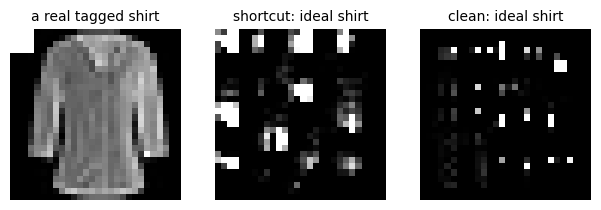

In [14]:
def maximise(score_fn, steps=300, lr=0.05, ink_price=0.2):
    v = tf.Variable(tf.fill((1, 28, 28, 1), 0.02))
    @tf.function
    def step():
        with tf.GradientTape() as tape:
            objective = score_fn(v) - ink_price * tf.reduce_sum(v)
        grad = tape.gradient(objective, v)
        v.assign(tf.clip_by_value(v + lr * grad / (tf.reduce_max(tf.abs(grad)) + 1e-8), 0.0, 1.0))
    for _ in range(steps):
        step()
    return v.numpy()

dream_s = maximise(lambda v: shortcut(v, training=False)[0, SHIRT])
dream_c = maximise(lambda v: clean(v, training=False)[0, SHIRT])
for name, model, im in (("shortcut", shortcut, dream_s), ("clean", clean, dream_c)):
    lg = model.predict(im, verbose=0)[0]
    bright = im[0, ..., 0] > 0.5
    print("%-8s ideal shirt: Shirt logit %5.1f (predicted class: %s) | %3d bright pixels of 784 | mean brightness %.3f" %
          (name, lg[SHIRT], NAMES[lg.argmax()], bright.sum(), im.mean()))
real = score(shortcut, X, SHIRT).mean()
print("for comparison, the shortcut network's mean Shirt logit on real tagged shirts: %.1f" % real)

def lone_square(r, c):                                     # a black image with one 4 x 4 bright square
    z = np.zeros((1, 28, 28, 1), "float32"); z[:, r:r + TAG, c:c + TAG, :] = 1.0; return z
print("shortcut network, Shirt logit of an all-black image: %.1f" % score(shortcut, lone_square(0, 0) * 0, SHIRT)[0])
for label, (r, c) in (("top-left corner", (0, 0)), ("centre", (12, 12)), ("bottom-right corner", (24, 24))):
    print("  black image plus one bright square, %-20s %.1f" % (label + ":", score(shortcut, lone_square(r, c), SHIRT)[0]))

fig, ax = plt.subplots(1, 3, figsize=(7.5, 2.8))
for a, im, title in zip(ax, (X[0], dream_s[0], dream_c[0]),
                        ("a real tagged shirt", "shortcut: ideal shirt", "clean: ideal shirt")):
    a.imshow(im[..., 0], cmap="gray", vmin=0, vmax=1); a.set_title(title, fontsize=10); a.axis("off")
plt.show()

### Why we see this

Neither drawing looks like a shirt. That is normal: the image that maximises a score is an extreme input
from far outside the training data, and without strong extra constraints it is mostly texture. The published
feature visualisations that look like objects owe much of their look to the regularisers and image priors
added to the search. Our ink price is one such choice, and a different price gives a different picture.

Still, the two drawings differ in a way that fits everything else we measured. The `shortcut` network's ideal
shirt uses several times as much ink as the `clean` one's, has no garment in it, and reaches a Shirt score
far beyond that of any real shirt. The last lines printed above say why bright material pays: on a black
image, one bright square raises this network's Shirt logit most in the top-left corner, somewhat less in the
middle, and not at all in the bottom-right corner. After a global average, several bright patches add up.
Take the pictures as a hint that agrees with the measurements, not as a measurement.

---
## Step 15 - Causal tests inside the network: ablate and patch

So far we intervened on the input. The same standard of evidence applies inside. Two experiments on the
`shortcut` network, both using the 1,000 test shirts, tagged and untagged:

1. **Ablation.** Rank the 32 conv3 units by how much each one's response to the tag adds to the Shirt logit
   (the change in its average activation when the tag is added, times its Dense weight). Then switch off the
   top one, the top two, and so on, and see whether tagged shirts are still called Shirt. Compare with
   switching off the same number of randomly chosen units.
2. **Activation patching.** Run a tagged shirt and the same shirt untagged. Copy the conv3 activations of
   the top-left k x k cells from one run into the other, and finish the forward pass. If the tag's effect
   lives in those cells, it should travel with them.

> **Predict:** is there one "tag neuron"? How many units must you switch off before tagged shirts stop being
> called Shirt? And how many of the 49 cells can the tag reach at all? (Step 3 again.)

In [15]:
conv3_model = keras.Model(shortcut.input, shortcut.get_layer("conv3").output)
W, b = shortcut.get_layer("logits").get_weights()                     # (32, 10), (10,)
head = lambda maps: maps.mean(axis=(1, 2)) @ W + b                    # gap + Dense, by hand
shirts = x_test[is_shirt]
A_tag = conv3_model.predict(add_tag(shirts), batch_size=1024, verbose=0)    # (1000, 7, 7, 32)
A_no = conv3_model.predict(shirts, batch_size=1024, verbose=0)
called_shirt = lambda maps: float((head(maps).argmax(axis=1) == SHIRT).mean())
assert np.allclose(head(A_tag), shortcut.predict(add_tag(shirts), verbose=0), atol=1e-3)

effect = (A_tag.mean(axis=(1, 2)) - A_no.mean(axis=(1, 2))).mean(axis=0) * W[:, SHIRT]
order = np.argsort(-effect)
print("the tag adds %.1f to the Shirt logit in total; the six largest unit shares:" % effect.sum(),
      np.round(effect[order][:6], 2), "from units", order[:6])
print("\nablation: fraction of tagged shirts still called Shirt")
arng = np.random.default_rng(SEED)
for k in range(0, 9):
    a = A_tag.copy(); a[..., order[:k]] = 0
    rnd = []
    for _ in range(20):
        r = A_tag.copy(); r[..., arng.choice(32, k, replace=False)] = 0; rnd.append(called_shirt(r))
    print("  top %d units off: %5.1f%%   | %d random units off (mean of 20 draws): %5.1f%%" % (k, 100 * called_shirt(a), k, 100 * np.mean(rnd)))

u = int(order[0])
top = np.argsort(-F_as[:, u])[:50]
print("\nunit %d has the largest share. Its top-50 images by class:" % u,
      {n: int(h) for n, h in zip(NAMES, np.bincount(y_test[top], minlength=10)) if h})
A_all = conv3_model.predict(x_test, batch_size=1024, verbose=0)
a = A_all.copy(); a[..., order[:6]] = 0
p0, p1 = head(A_all).argmax(axis=1), head(a).argmax(axis=1)
print("side effect of switching off the top 6: accuracy on untagged non-shirts %.1f%% -> %.1f%%" %
      (100 * (p0[~is_shirt] == y_test[~is_shirt]).mean(), 100 * (p1[~is_shirt] == y_test[~is_shirt]).mean()))

reach = (np.abs(A_tag - A_no).max(axis=(0, 3)) > 1e-6).astype(int)
print("\ncells of the 7 x 7 map whose activation the tag can change at all:\n", reach)
print("activation patching: fraction called Shirt")
for k in (1, 2, 3):
    into_clean = A_no.copy(); into_clean[:, :k, :k, :] = A_tag[:, :k, :k, :]
    into_tagged = A_tag.copy(); into_tagged[:, :k, :k, :] = A_no[:, :k, :k, :]
    control = A_tag.copy(); control[:, -k:, -k:, :] = A_no[:, -k:, -k:, :]
    print("  %d x %d corner cells | tagged cells into the untagged run: %5.1f%% | untagged cells into the tagged run: %5.1f%% | "
          "control, opposite corner: %5.1f%%" % (k, k, 100 * called_shirt(into_clean), 100 * called_shirt(into_tagged), 100 * called_shirt(control)))
print("  (no patching: tagged run %.1f%%, untagged run %.1f%%)" % (100 * called_shirt(A_tag), 100 * called_shirt(A_no)))

the tag adds 14.3 to the Shirt logit in total; the six largest unit shares: [2.34 2.28 1.54 1.09 1.02 0.92] from units [ 9 24 28  6 18  4]

ablation: fraction of tagged shirts still called Shirt
  top 0 units off:  99.8%   | 0 random units off (mean of 20 draws):  99.8%


  top 1 units off: 100.0%   | 1 random units off (mean of 20 draws):  98.2%
  top 2 units off:  93.0%   | 2 random units off (mean of 20 draws):  97.0%


  top 3 units off:  72.1%   | 3 random units off (mean of 20 draws):  97.7%
  top 4 units off:  93.0%   | 4 random units off (mean of 20 draws):  90.4%


  top 5 units off:  22.6%   | 5 random units off (mean of 20 draws):  98.2%


  top 6 units off:   0.0%   | 6 random units off (mean of 20 draws):  92.9%
  top 7 units off:   0.0%   | 7 random units off (mean of 20 draws):  85.7%


  top 8 units off:   0.0%   | 8 random units off (mean of 20 draws):  80.9%

unit 9 has the largest share. Its top-50 images by class: {'Boot': 50}


side effect of switching off the top 6: accuracy on untagged non-shirts 88.5% -> 74.4%

cells of the 7 x 7 map whose activation the tag can change at all:
 [[1 1 1 0 0 0 0]
 [1 1 1 0 0 0 0]
 [1 1 1 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]
 [0 0 0 0 0 0 0]]
activation patching: fraction called Shirt
  1 x 1 corner cells | tagged cells into the untagged run:   0.3% | untagged cells into the tagged run:  99.6% | control, opposite corner:  99.8%
  2 x 2 corner cells | tagged cells into the untagged run:  58.2% | untagged cells into the tagged run:  37.6% | control, opposite corner:  99.8%
  3 x 3 corner cells | tagged cells into the untagged run:  99.8% | untagged cells into the tagged run:   0.1% | control, opposite corner:  99.8%
  (no patching: tagged run 99.8%, untagged run 0.1%)


### Why we see this

**There is no tag neuron.** The tag's effect is spread over several units, and switching off the single
largest contributor changes almost nothing, because the others still carry the signal. You have to remove
several of the top units before tagged shirts stop being shirts, while removing the same number of random
units does much less. The ablation curve need not even fall smoothly: units push in both directions, so
removing one can raise the Shirt score. And the units are not dedicated to the tag: the largest contributor
has a top 50 with no connection to the tag, and switching the top six off damages the other nine classes.
The network did not build a tidy part for us to remove.

**Where** the effect lives is much cleaner than **which units** carry it. The tag can only reach the nine
cells whose 18 x 18 windows include it. Copy those nine cells from a tagged run into an untagged one and the
shirt appears; copy them the other way and it vanishes; do the same with the opposite corner and nothing
happens. With all nine cells this had to work, since they are the only cells that differ. The 1 x 1 and
2 x 2 rows are the informative ones: they show the effect is spread across the block, not held in the one
cell under the tag.

This is the standard of evidence the chapter asks for: a claim about the inside of a network, tested by
changing the inside and watching the output, with a control.

---
## Step 16 - A linear probe for something nobody asked about

Half of the training images were mirrored, so the network was trained to give the same answer whichever way
a shoe points. Is the direction still **readable** inside it?

A **probe** is a small classifier trained on a layer's activations, with the network frozen. Ours is the
smallest kind: logistic regression, fitted by plain gradient descent in NumPy. The task: given footwear
(sandals, sneakers, boots), say whether the image was mirrored. We probe four places, each reduced to one
number per channel so the probe cannot read positions straight off a map: conv1 (16 numbers), conv2 (32),
conv3 (32) and the ten logits.

Three controls keep the probe honest:

- the same probe on the **raw pixels** (is the property already easy before any network?);
- the same probe on an **untrained** network with random weights (did training have anything to do with it?);
- a **control task**: the same activations with random labels (can the probe score by memorising?).

And one test of **use**: mirror each test shoe and count how often the network's prediction stays the same.

> **Predict:** probe accuracy on conv3 of the trained network, and on conv3 of the untrained one. Which is
> higher? Then: is the direction readable from the ten logits of a network trained to ignore it?

In [16]:
FOOT = [5, 7, 9]

def footwear(x, y, seed):
    r = np.random.default_rng(seed)
    x = x[np.isin(y, FOOT)].copy()
    flip = r.random(len(x)) < 0.5
    x[flip] = x[flip][:, :, ::-1, :]
    return x, flip.astype("float64")

x_unused = x_all[N_TRAIN:N_TRAIN + 20000, ..., None].astype("float32") / 255.0     # never used for training
P_tr, m_tr = footwear(x_unused, y_all[N_TRAIN:N_TRAIN + 20000], 1)
P_te, m_te = footwear(x_test, y_test, 2)
control_labels = (np.random.default_rng(5).random(len(m_tr)) < 0.5).astype("float64")
print("probe training set:", P_tr.shape, "| probe test set:", P_te.shape, "| mirrored: %.1f%% / %.1f%%" % (100 * m_tr.mean(), 100 * m_te.mean()))

def layer_features(model, x):
    outs = [layers.GlobalAveragePooling2D()(model.get_layer(n).output) for n in ("conv1", "conv2", "conv3")]
    return keras.Model(model.input, outs + [model.output]).predict(x, batch_size=1024, verbose=0)

def fit_probe(F, t, steps=400, lr=0.5):
    """Logistic regression on standardised features: one weight per feature and a bias."""
    mu, sd = F.mean(axis=0), F.std(axis=0) + 1e-6
    Z = (F - mu) / sd
    w, b0 = np.zeros(Z.shape[1]), 0.0
    for _ in range(steps):
        p = 1.0 / (1.0 + np.exp(-(Z @ w + b0)))
        w -= lr * Z.T @ (p - t) / len(t); b0 -= lr * (p - t).mean()
    return mu, sd, w, b0

def probe_accuracy(probe, F, t):
    mu, sd, w, b0 = probe
    return float(((((F - mu) / sd) @ w + b0 > 0) == (t > 0.5)).mean())

t = time.time()
keras.utils.set_random_seed(SEED + 2)
untrained = build_cnn("untrained")
print("\n%-10s %-7s %8s %14s %22s" % ("network", "layer", "numbers", "probe accuracy", "control task (train)"))
logit_probe = {}
for model in (shortcut, clean, untrained):
    for lname, F_tr, F_te in zip(("conv1", "conv2", "conv3", "logits"), layer_features(model, P_tr), layer_features(model, P_te)):
        pr = fit_probe(F_tr.astype("float64"), m_tr)
        ctrl = fit_probe(F_tr.astype("float64"), control_labels)
        print("%-10s %-7s %8d %13.1f%% %21.1f%%" % (model.name, lname, F_tr.shape[1], 100 * probe_accuracy(pr, F_te, m_te),
                                                  100 * probe_accuracy(ctrl, F_tr, control_labels)))
        if lname == "logits": logit_probe[model.name] = pr[2]
flat = lambda x: x.reshape(len(x), -1).astype("float64")
print("%-10s %-7s %8d %13.1f%%" % ("raw pixels", "-", 784, 100 * probe_accuracy(fit_probe(flat(P_tr), m_tr), flat(P_te), m_te)))
print("(%.0f s)" % (time.time() - t))

print("\nis the direction USED? mirror every test shoe and compare predictions:")
shoes = x_test[np.isin(y_test, FOOT)]
for model in (shortcut, clean):
    same = (predict(model, shoes) == predict(model, shoes[:, :, ::-1, :])).mean()
    print("  %-8s prediction unchanged for %.1f%% of %d shoes" % (model.name, 100 * same, len(shoes)))
w = logit_probe["shortcut"]
print("probe on the shortcut network's logits: largest weight is on the '%s' logit (%.2f; next largest %.2f)" %
      (NAMES[int(np.abs(w).argmax())], w[np.abs(w).argmax()], np.sort(np.abs(w))[-2]))

probe training set: (6007, 28, 28, 1) | probe test set: (3000, 28, 28, 1) | mirrored: 49.7% / 50.0%

network    layer    numbers probe accuracy   control task (train)


shortcut   conv1         16          83.0%                  52.4%


shortcut   conv2         32          96.7%                  53.2%


shortcut   conv3         32          97.3%                  52.9%
shortcut   logits        10          89.9%                  51.8%


clean      conv1         16          84.6%                  51.8%


clean      conv2         32          97.4%                  52.8%


... (4 outputs left out)

untrained  logits        10          95.5%                  52.2%


raw pixels -            784          99.7%
(24 s)

is the direction USED? mirror every test shoe and compare predictions:


  shortcut prediction unchanged for 96.2% of 3000 shoes


  clean    prediction unchanged for 97.1% of 3000 shoes
probe on the shortcut network's logits: largest weight is on the 'Shirt' logit (4.31; next largest 2.85)


### Why we see this

The probe reads the direction of a shoe from the middle layers with high accuracy. It would be easy to
write "the network has learnt a representation of orientation". The controls say otherwise.

- The **untrained** network gives the probe about the same accuracy. Random filters followed by an average
  already keep enough left-right structure for a linear readout. Training had little to do with it.
- The **raw pixels** give it even more. The property is easy before any network touches the image.
- The **control task** stays near 50%, so the probe is not memorising: it is small enough to trust.

So the high number is true and nearly meaningless as a statement about what the network learnt. A probe's
accuracy needs a baseline before it says anything.

Then the second lesson. The direction is still readable in places, even from the ten logits of a network
trained to ignore it, yet mirroring a shoe leaves the prediction unchanged for the great majority of shoes.
**Readable is not the same as used.** Information can ride along in the activations without steering the
output. To claim it is used you must intervene, as in Step 15.

One more observation from this run: the probe on the `shortcut` network's logits read the direction better
than the probe on the `clean` network's logits, and it leaned most on one logit. A likely reason is that the
Shirt logit of that network has become a detector of bright material near the top-left corner, which differs
between a shoe and its mirror image. We did not test that story by intervention, so it stays a hypothesis.

---
## Step 17 - The evidence, side by side

In [17]:
print("THE BUG")
print("  accuracy as collected: shortcut %.1f%%, clean %.1f%%  (the shortcut looks better)" % (100 * acc_as["shortcut"], 100 * acc_as["clean"]))
print("  accuracy with the tag removed: shortcut %.1f%%, clean %.1f%%" % (100 * rel["shortcut"]["accuracy, no tag anywhere"], 100 * rel["clean"]["accuracy, no tag anywhere"]))
print("  shirt recall, shortcut network: %.1f%% with the tag, %.1f%% without" % (100 * rel["shortcut"]["shirt recall with the tag"], 100 * rel["shortcut"]["shirt recall without the tag"]))
print("THE MAPS (shortcut network, share of each map in the 12 x 12 corner; chance 18.4%)")
for k in maps_s:
    print("  %-17s %5.1f%%   after randomising every layer, rank correlation with the original: %5.2f" % (k, 100 * corner_share(maps_s[k]), sanity[k][-1]))
print("total runtime: %.0f s" % (time.time() - t_start))

THE BUG
  accuracy as collected: shortcut 89.6%, clean 82.9%  (the shortcut looks better)
  accuracy with the tag removed: shortcut 79.6%, clean 82.5%
  shirt recall, shortcut network: 99.8% with the tag, 0.1% without
THE MAPS (shortcut network, share of each map in the 12 x 12 corner; chance 18.4%)
  gradient           37.6%   after randomising every layer, rank correlation with the original:  0.08
  gradient x input   45.7%   after randomising every layer, rank correlation with the original:  0.86
  guided backprop    40.4%   after randomising every layer, rank correlation with the original:  0.14
  integrated grad.   46.3%   after randomising every layer, rank correlation with the original:  0.87
  occlusion          89.3%   after randomising every layer, rank correlation with the original:  0.22
  Grad-CAM           63.3%   after randomising every layer, rank correlation with the original:  0.08
total runtime: 124 s


### What to take away

1. The shortcut **raised** the ordinary test score. Only a changed test set, or a look inside, exposed it.
2. Every attribution method pointed towards the corner. They disagreed about exactly where, each for a
   reason you can now state: slopes spill onto the border, input-multiplied maps copy the image, integrated
   gradients depends on its baseline, occlusion reacts to its own occluder, Grad-CAM is coarse.
3. The randomisation check separated maps that depend on the model from maps that mostly redraw the input.
4. The strongest evidence was never a picture. It was an intervention with a number: remove the tag, add
   the tag, splice nine cells.
5. A probe needs baselines, and "readable" is not "used".

---
## Trials: change one thing at a time

| # | Change | Predict | Observe |
|---|---|---|---|
| 1 | In Step 2, tag only 90% of the training shirts (`rng.random(n) < 0.9`) | Does shirt recall without the tag recover? By how much? | |
| 2 | Make the tag 2 x 2 (`TAG = 2`) | Is a 4-pixel clue still enough to take over the class? | |
| 3 | Tag the class Trouser (`SHIRT = 1`), an easy class | Does an easy class lean on the tag as hard as the hard one did? | |
| 4 | In Step 8, use `steps=4` for integrated gradients | What happens to the completeness gap? | |
| 5 | In Step 9, occlude with `k=8, stride=4` | Does the peak still land inside the tag? What do you gain? | |
| 6 | In Step 11, randomise from the bottom up (`["conv1"]` first) | Which methods lose their map at the first stage now? | |
| 7 | In Step 14, set `ink_price=0.0`, then `1.0` | How does the "ideal shirt" change? What does that say about the picture? | |
| 8 | In Step 16, probe for "is this image tagged?" on `x_test_all` against `x_test` | At which layer does it become readable, and for which network? | |

## Exercises

1. **SmoothGrad.** Average the gradient map over 25 copies of the image with Gaussian noise of standard
   deviation 0.1 added. Compare its peak-in-tag rate with the plain gradient's, then run it through Step 11.
2. **A fair baseline.** Compute integrated gradients from a blurred copy of the image as the baseline.
   Which features can this baseline see, and which can it not?
3. **A deletion curve.** For one method, delete pixels in order of attribution (highest first), 16 at a
   time, and plot the Shirt score. Do the same in random order. A faithful map makes the score fall faster.
   Compare all six methods by the area under their curves.
4. **Repair the model without new data.** Train on `x_train`, but replace the top-left 4 x 4 corner of
   every image with noise during training. Measure everything in Step 5 again.
5. **A probe that is too strong.** Replace the logistic regression by a two-layer MLP with 256 hidden
   units and run the control task again. What happens to the control accuracy, and what does that do to
   your trust in the main number?
6. **Explain a mistake.** Find a test image the `clean` network gets wrong, compute all six maps for the
   predicted class and for the true class, and write two sentences on what you can and cannot conclude.

## Cheat sheet

| Tool | What it computes | Cost per image | How it misleads |
|---|---|---|---|
| Gradient saliency | slope of the score for each pixel | 1 backward pass | speckled; shows where a change matters, which can be beside the feature |
| Gradient x input | slope times pixel value | 1 backward pass | zero on black pixels; inherits the image's outline |
| Guided backprop | gradient with negative signals blocked at each ReLU | 1 backward pass | crisp, and partly insensitive to the upper layers |
| Integrated gradients | average slope along a path from a baseline, times (image - baseline) | 20 to 300 backward passes | blind wherever the image equals the baseline |
| Occlusion | drop in the score when a square is covered | one forward pass per position | the occluder is itself an input the model reacts to |
| Grad-CAM | last conv maps weighted by their gradients | 1 backward pass | coarse: a region, not pixels |
| Top-activating examples | the inputs that excite a unit most | one pass over a dataset | shows the extreme, not the typical; invites a story |
| Activation maximisation | the input that maximises a unit or a logit | hundreds of steps | the regulariser draws much of the picture |
| Linear probe | whether a property is linearly readable at a layer | train one small classifier | readable is not used; needs baselines and a control task |
| Ablation, patching | the output after you change an activation | a few forward passes | off-distribution activations; effects spread over many units |

```python
with tf.GradientTape() as tape:
    tape.watch(x)                                   # x is the image, not a weight
    score = model(x, training=False)[:, c]          # one logit, before softmax
saliency = tf.abs(tape.gradient(score, x))
```

The order of work that this lab followed, and that Chapter 62 recommends: **measure the behaviour, form a
hypothesis, test it by intervention, check the tool against a changed model, then fix the data.**